# 1 Anomaly detection

Stage 1 of the paper: the dataset, the downtime filter, and the anomaly detection with a normal behavior model and a CUSUM detector per component. Everything is computed from the stored residuals in `results/stage1/` (see notebook 0) and the CARE-to-Compare dataset in `data/`.

Figures and tables that appear in the paper are marked **Paper**. The others are extra and not in the paper. Figures are written to `outputs/1_anomaly_detection/`, in `paper/` and `extra/`.

With `RESULTS = 'retrained'`, the notebook reads the results of notebook 0 in `results_retrained/` instead, and writes its figures to `outputs_retrained/`.

In [1]:
%matplotlib inline
import pandas as pd
from scipy.stats import spearmanr

from two_stage import config as cfg, data, plots, stage1

RESULTS = 'paper'

cfg.use_results(RESULTS)
pd.set_option('display.precision', 2)
PAPER = cfg.figure_dir('1_anomaly_detection') / 'paper'
EXTRA = cfg.figure_dir('1_anomaly_detection') / 'extra'

info = data.load_info()
runs = stage1.runs(info)
residuals = stage1.load_all_residuals(runs)

## Data and preprocessing

**Paper, Table 3.** Wind farm B of the CARE-to-Compare dataset. The main bearing failure and the two rotor bearing failures count as one component, the bearing.

In [2]:
data.dataset_summary(info).to_frame()

,Wind farm B
Total turbines,9
Turbines with anomalies,6
Time series,15
Anomalies,6
Healthy time series,9
Features,252
Available components,2


**Paper, Fig. 4.** Records removed by the downtime filter, which keeps only status 0 (normal operation).

removed_pct        records       
                          min    max     min    max
period                                             
prediction period        0.26  12.53    1297  14113
training period          6.32  16.30   52041  52559

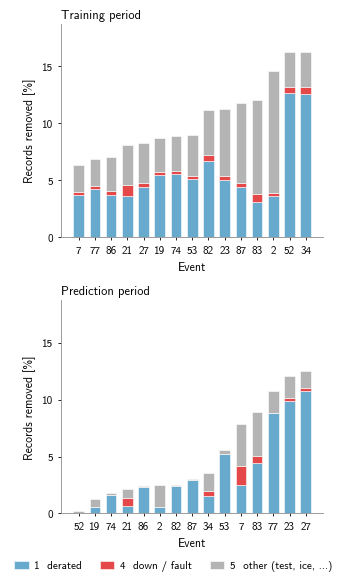

In [3]:
removed = data.removed_records(info)
component = info['component'].map(cfg.COMPONENT_OF)
order = [int(e) for e in pd.concat([info[component == 'transformer'], info[component == 'bearing'],
                                    info[info['event_label'] == 'normal']])['event_id']]
fig = plots.downtime_filter(removed, order)
plots.save(fig, PAPER / 'fig04_downtime_filter')
removed.groupby('period')[['removed_pct', 'records']].agg(['min', 'max'])

## Detector settings

The slack $k$ and the threshold percentile $p$ of each detector are chosen on the CARE score over all cases of its component.

In [4]:
grid = stage1.settings_grid(runs, residuals)
settings = stage1.choose_settings(grid)
settings

{'bearing': (0.25, 99.9), 'transformer': (1.0, 99.9)}

Extra: the CARE score of every setting.

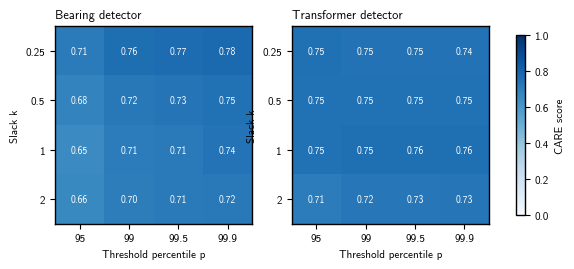

In [5]:
fig = plots.care_grid(grid)
plots.save(fig, EXTRA / 'care_grid')

**Paper, Table 6.** Comparison with the reference implementation of O'Connor et al. (2026), on the cases of their study: bearing failures 27 and 77 and healthy events 2 and 21. The setting is chosen on these cases, as in their study.

In [6]:
reference = stage1.settings_grid(runs, residuals, ['bearing'], stage1.REFERENCE_CASES)
reference.sort_values('CARE', ascending=False).head(1)

,component,k,p,Coverage,Accuracy,Reliability,Earliness,CARE
4,bearing,0.5,95.0,0.96,1.0,1.0,0.81,0.95


## Results per event

**Paper, Tables 7 and 8.** First alarm of each detector, the component the failure is attributed to (the detector that alarms first), the length of the prediction period, and the time each detector spends above its threshold, in operating days.

In [7]:
results = stage1.event_results(info, residuals, settings)
table = pd.DataFrame({
    'event': results['event'].map(cfg.failure_label),
    'true component': results['true_component'].fillna('--'),
    'prediction period (days)': results['span_days'],
    **{f'{c} first alarm': results[f'{c}_first_alarm'].dt.date.astype(str).replace('NaT', '--') for c in cfg.COMPONENTS},
    **{f'{c} days flagged': results[f'{c}_flagged_days'] for c in cfg.COMPONENTS},
    'attributed': results['attributed'].fillna('--'),
})
table.round(1)

,event,true component,prediction period (days),bearing first alarm,transformer first alarm,bearing days flagged,transformer days flagged,attributed
0,T1 (34),transformer,26.8,2023-08-26,2023-08-25,22.6,26.3,transformer
1,T2 (7),transformer,33.9,2023-07-03,2023-07-08,31.8,26.1,bearing
2,B1 (53),bearing,39.4,2024-01-02,2024-01-05,32.2,29.7,bearing
3,B2 (27),bearing,60.1,2023-09-24,--,35.8,NaN,bearing
4,T3 (19),transformer,25.4,--,2023-02-05,NaN,22.5,transformer
5,B3 (77),bearing,57.1,2023-05-30,2023-06-14,57.1,43.8,bearing
6,83,--,89.0,2023-08-06,2023-07-22,53.1,68.3,transformer
7,52,--,18.7,--,2023-07-20,NaN,1.5,transformer
8,21,--,8.6,--,--,NaN,NaN,--
9,2,--,14.8,--,2023-08-12,NaN,11.8,transformer


Numbers in the text: the lead time of the first alarm before the assumed failure point, the margin between the two detectors, and the healthy references with an alarm.

In [8]:
failures = info[info['event_label'] == 'anomaly'].set_index('event_id')
summary = results.set_index('event')
first = summary[[f'{c}_first_alarm' for c in cfg.COMPONENTS]].min(axis=1)
lead = (failures['event_end'].dt.normalize() - first.loc[failures.index].dt.normalize()).dt.days
margin = (summary['bearing_first_alarm'].dt.normalize() - summary['transformer_first_alarm'].dt.normalize()).dt.days
healthy = summary[summary['true_component'].isna()]
alarmed = healthy[[f'{c}_first_alarm' for c in cfg.COMPONENTS]].notna().any(axis=1)
print('lead time (calendar days):', dict(lead.rename(index=cfg.FAILURE_NAME)))
print('days between the two first alarms (bearing - transformer):', dict(margin.loc[failures.index].dropna().rename(index=cfg.FAILURE_NAME)))
print(f'healthy references with an alarm: {alarmed.sum()} of {len(healthy)}')
print(f"share of the T2 prediction period flagged by the bearing detector: {summary.loc[7, 'bearing_flagged_fraction']:.1%}")

lead time (calendar days): {'T1': np.int64(21), 'T2': np.int64(29), 'B1': np.int64(35), 'B2': np.int64(38), 'T3': np.int64(18), 'B3': np.int64(62)}
days between the two first alarms (bearing - transformer): {'T1': np.float64(1.0), 'T2': np.float64(-5.0), 'B1': np.float64(-3.0), 'B3': np.float64(-15.0)}
healthy references with an alarm: 7 of 9
share of the T2 prediction period flagged by the bearing detector: 93.9%


## Detection plots

**Paper, Fig. 10.** The transformer detector on T2 (event 7).

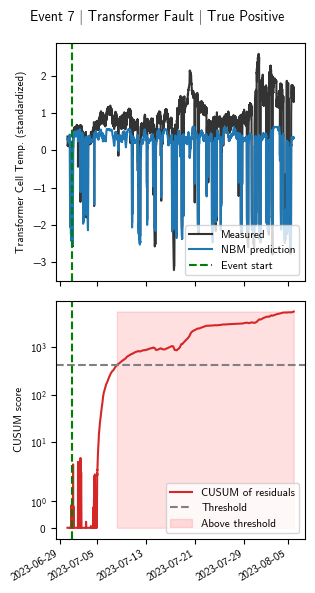

In [9]:
event_start = failures.loc[7, 'event_start']
fig = plots.detection(stage1.detect(residuals[(7, 'transformer')], *settings['transformer']),
                      'Event 7 | Transformer Fault | True Positive', 'transformer', event_start)
plots.save(fig, PAPER / 'fig10_detection_T2_transformer')

**Paper, Fig. 11.** The transformer detector on the healthy event 2.

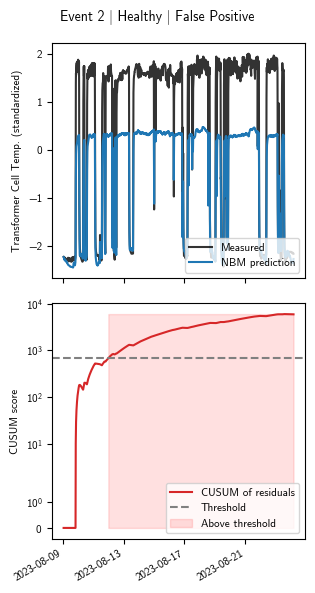

In [10]:
fig = plots.detection(stage1.detect(residuals[(2, 'transformer')], *settings['transformer']),
                      'Event 2 | Healthy | False Positive', 'transformer')
plots.save(fig, PAPER / 'fig11_detection_event2_transformer')

Extra: both detectors on every failure, and every detector that raises a false alarm on a healthy event.

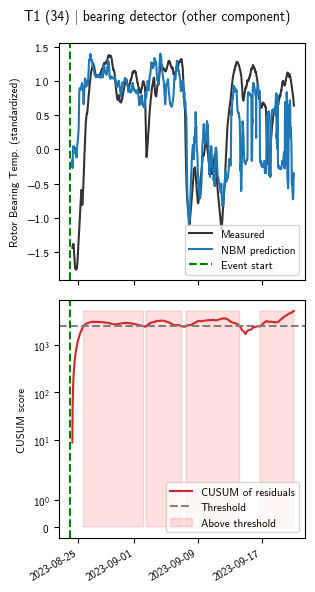

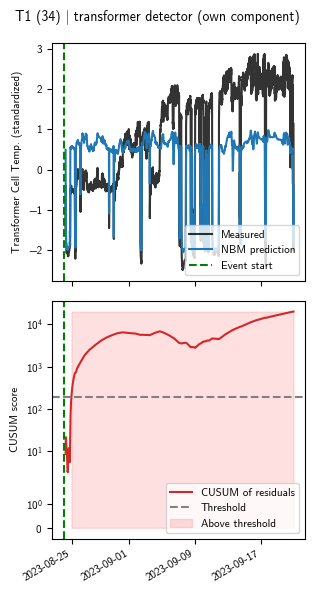

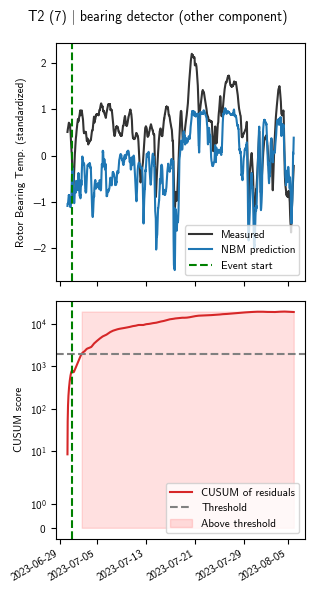

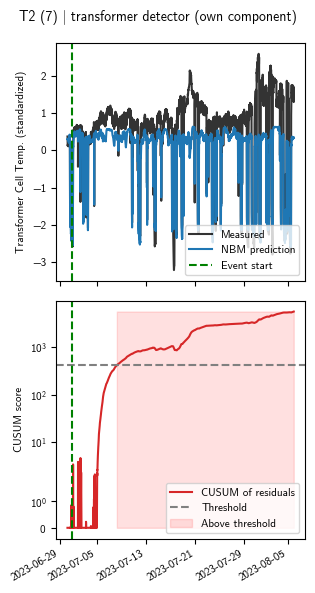

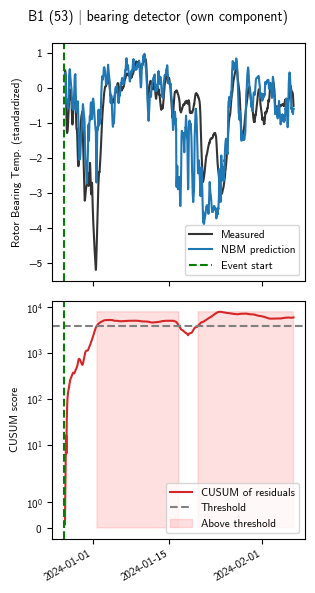

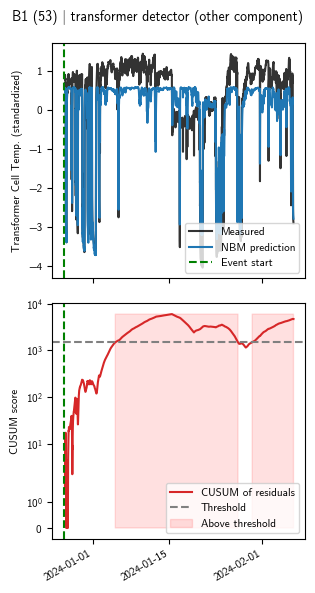

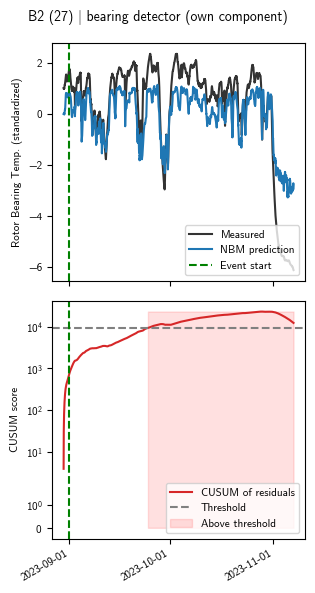

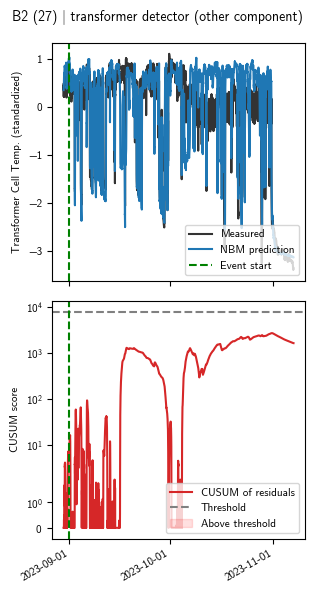

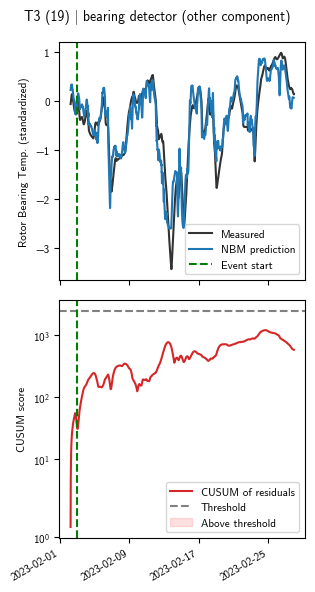

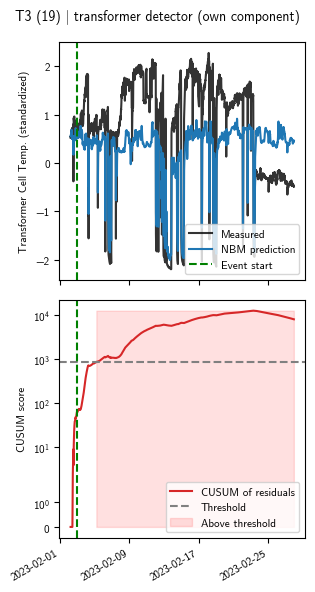

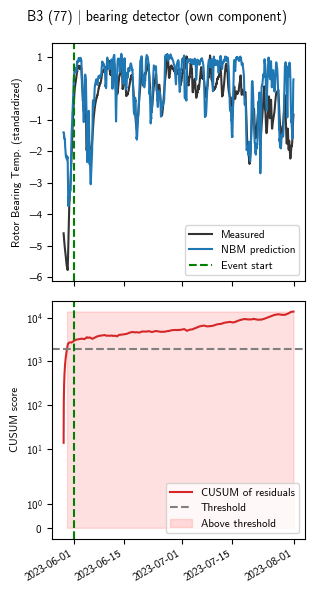

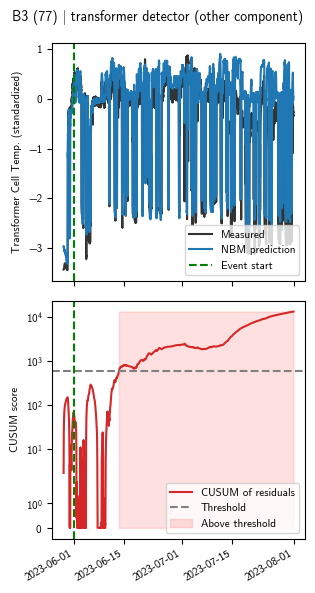

In [11]:
for event, row in failures.iterrows():
    for component in cfg.COMPONENTS:
        kind = 'own component' if cfg.COMPONENT_OF[row['component']] == component else 'other component'
        title = f'{cfg.failure_label(event)} | {component} detector ({kind})'
        fig = plots.detection(stage1.detect(residuals[(event, component)], *settings[component]), title, component,
                              row['event_start'])
        plots.save(fig, EXTRA / 'detections' / f'{cfg.FAILURE_NAME[event]}_event{event}_{component}')

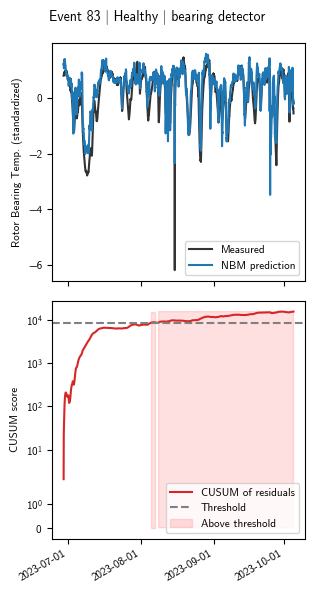

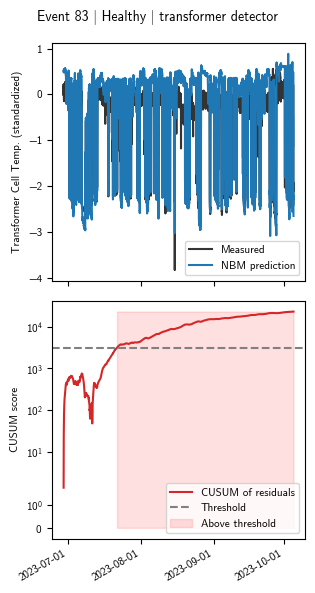

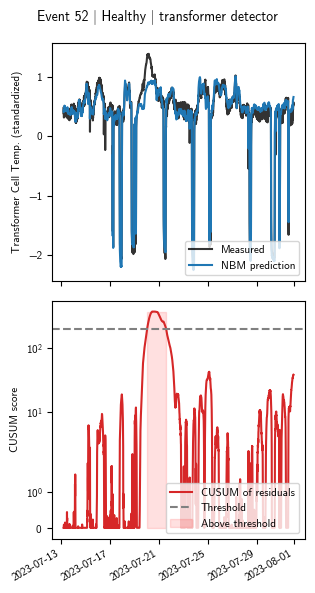

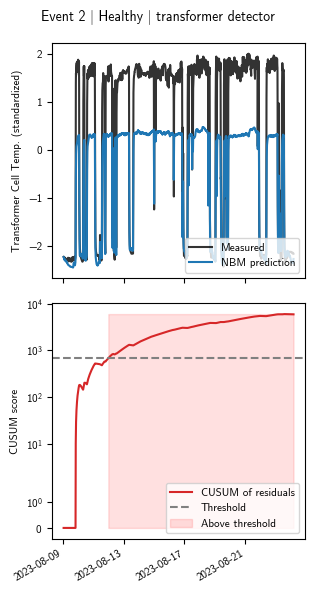

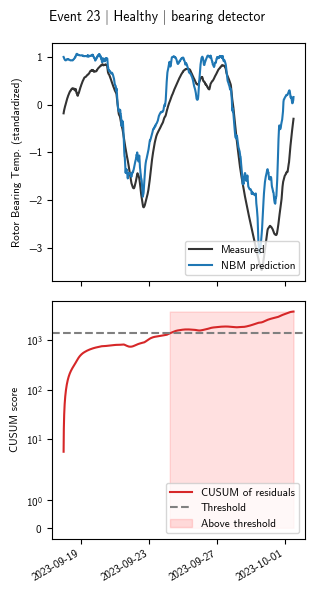

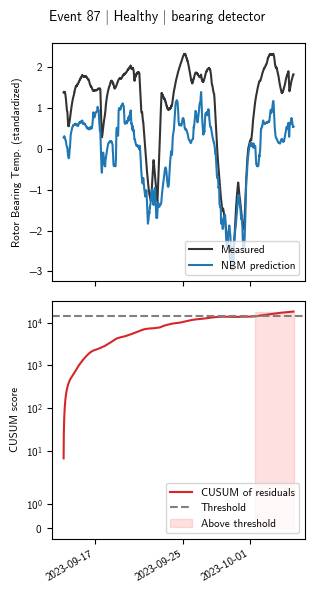

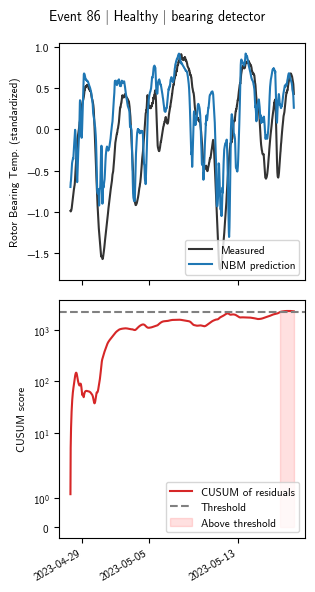

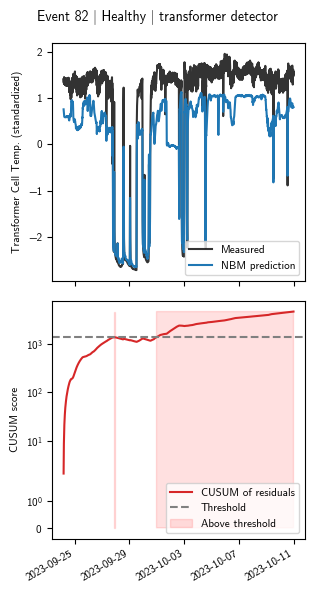

In [12]:
for event in healthy.index:
    for component in cfg.COMPONENTS:
        if pd.notna(healthy.loc[event, f'{component}_first_alarm']):
            fig = plots.detection(stage1.detect(residuals[(event, component)], *settings[component]),
                                  f'Event {event} | Healthy | {component} detector', component)
            plots.save(fig, EXTRA / 'detections' / f'healthy_event{event}_{component}')

## False alarms

Numbers in the text: the thresholds of the detectors, and the mean residual of every detector on the healthy events over the prediction period, in MADs of its training residuals.

In [13]:
offsets = stage1.residual_offsets(info, residuals, settings)
for component, part in offsets.groupby('component'):
    print(f"{component} thresholds: {part['threshold'].min():,.0f} to {part['threshold'].max():,.0f}")
healthy_offsets = offsets[offsets['healthy']]
size = healthy_offsets['offset'].abs()
print(f"median |offset|: {size[healthy_offsets['alarm']].median():.2f} MAD for the {healthy_offsets['alarm'].sum()} alarming detectors, "
      f"{size[~healthy_offsets['alarm']].median():.2f} MAD for the other {(~healthy_offsets['alarm']).sum()}")
print('Spearman correlation of |offset| and flagged fraction:', spearmanr(size, healthy_offsets['flagged_fraction']))
healthy_offsets.sort_values('offset', key=abs, ascending=False).head(5)

bearing thresholds: 1,387 to 13,992
transformer thresholds: 190 to 28,643
median |offset|: 2.34 MAD for the 8 alarming detectors, 0.46 MAD for the other 10
Spearman correlation of |offset| and flagged fraction: SignificanceResult(statistic=np.float64(0.5676070917784733), pvalue=np.float64(0.01400993766877693))


,event,component,healthy,offset,threshold,alarm,flagged_fraction
25,74,transformer,True,6.47,28642.93,False,0.00
22,87,bearing,True,6.17,13992.20,True,0.17
19,2,transformer,True,3.61,674.31,True,0.80
29,82,transformer,True,2.88,1378.25,True,0.59
13,83,transformer,True,-2.51,3121.38,True,0.77


Event 2: the conditions of the prediction period against the training average (normal-status records).

In [14]:
raw = data.load_raw(2, fix_labels=False)
raw = raw[raw['status_type_id'] == cfg.NORMAL_STATUS]
train, prediction = raw[raw['train_test'] == 'train'], raw[raw['train_test'] == 'prediction']
temperature = prediction['sensor_8_avg'].mean() - train['sensor_8_avg'].mean()
power = prediction['power_62_avg'].mean() / train['power_62_avg'].mean() - 1
print(f'outside temperature: {temperature:+.1f} °C, power output: {power:+.0%}')

outside temperature: +9.6 °C, power output: -72%
